# Balanced arXiv IMSTE experiments

This notebook keeps the full prepared vector cache intact, then selects a reproducible subset for faster controlled experiments. The default requests 32,000 unique papers balanced across the eight domains (4,000 per domain); if a smaller source dataset cannot supply that many unique examples per class, the sample size is capped to the minority-class limit. Set `SAMPLE_MODE` to `full` or `random` to compare other sampling strategies. Balanced selection never duplicates minority papers.

It fits UMAP once for this exact subset, compares PCA/multilevel and UMAP-warm-started IMSTE, and tests adding FAMST candidate neighbors as extra local attractions. It reports neighborhood fidelity, domain purity, normalized local radius, and runtime. Subset and model settings are included in cache identities.

In [1]:
from pathlib import Path
import sys
import json
import hashlib
import time
import numpy as np
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "pyproject.toml").exists() and (PROJECT_ROOT.parent / "pyproject.toml").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "notebooks" / "src"))
from arxiv_dataset import load_arxiv_dataset
from arxiv_imste import select_arxiv_experiment_subset

DATA_DIR = PROJECT_ROOT / "data" / "arxiv"
CACHE_DIR = DATA_DIR / "cache"
EXPERIMENT_CACHE_DIR = CACHE_DIR / "balanced_experiments"
EXPERIMENT_CACHE_DIR.mkdir(parents=True, exist_ok=True)
papers, X_full, data_manifest = load_arxiv_dataset(DATA_DIR)

primary_category = papers["categories"].fillna("unknown").str.split().str[0]
archive = primary_category.str.split(".").str[0]
domain_names = {
    "cs": "computer science",
    "math": "mathematics",
    "eess": "engineering",
    "stat": "statistics",
    "q-bio": "biology",
    "q-fin": "finance",
    "econ": "economics",
}
domain = archive.map(domain_names).fillna("physics")
domain_order = domain.value_counts().index.tolist()
labels_full = pd.Categorical(domain, categories=domain_order)

# Change these controls to run a smaller, reproducible experiment.
SAMPLE_MODE = "balanced"  # "balanced", "random", or "full"
REQUESTED_SAMPLE_SIZE = 32_000
SAMPLE_RANDOM_STATE = int(data_manifest["random_state"])
if SAMPLE_MODE == "balanced":
    counts = np.unique(np.asarray(labels_full), return_counts=True)[1]
    SAMPLE_SIZE = min(REQUESTED_SAMPLE_SIZE, len(counts) * int(counts.min()))
    if SAMPLE_SIZE < REQUESTED_SAMPLE_SIZE:
        print(f"Balanced sample capped at {SAMPLE_SIZE:,} unique rows by the minority class size.")
else:
    SAMPLE_SIZE = REQUESTED_SAMPLE_SIZE
X_experiment, labels_experiment, experiment_data_id = select_arxiv_experiment_subset(
    X_full,
    labels_full,
    dataset_id=data_manifest["dataset_id"],
    mode=SAMPLE_MODE,
    sample_size=SAMPLE_SIZE,
    random_state=SAMPLE_RANDOM_STATE,
)
print(f"Source data: {len(X_full):,} papers × {X_full.shape[1]:,} features")
print(f"Experiment subset: {len(X_experiment):,} rows ({SAMPLE_MODE}), ID {experiment_data_id}")
print(pd.Series(np.asarray(labels_experiment)).value_counts().sort_index().to_string())

# Shared geometry settings. Keep these fixed when comparing initializations.
RANDOM_STATE = int(data_manifest["random_state"])
METRIC = "euclidean"
N_NEIGHBORS = 15
UMAP_EPOCHS = 200
IMSTE_N_MSTS = 5
IMSTE_N_EPOCHS = 100
IMSTE_BATCH_SIZE = 32768
IMSTE_LEARNING_RATE = 0.05
IMSTE_NEGATIVE_RATIO = 1
IMSTE_LAMBDA_REP = 0.05
IMSTE_LOGISTIC_MARGIN = 0.25
IMSTE_LOGISTIC_TEMPERATURE = 0.5
IMSTE_DEVICE = "mps"  # Set to "auto" or "cpu" when MPS is unavailable.
IMSTE_MST_NEIGHBOR_BACKEND = "rinnd"


Source data: 1,200,000 papers × 384 features
Experiment subset: 32,000 rows (balanced), ID c2e0ceee03fc5e6b00b2
biology             4000
computer science    4000
economics           4000
engineering         4000
finance             4000
mathematics         4000
physics             4000
statistics          4000


In [2]:
import umap

umap_settings = {
    "n_components": 2,
    "n_neighbors": N_NEIGHBORS,
    "min_dist": 0.1,
    "repulsion_strength": 4,
    "metric": METRIC,
    "compatibility_layout": False,
    "nearest_neighbor_backend": "rinnd",
    "init": "recursive",
    "random_state": RANDOM_STATE,
    "n_epochs": UMAP_EPOCHS,
}
umap_key = hashlib.sha256(
    json.dumps({"data_id": experiment_data_id, **umap_settings}, sort_keys=True).encode()
).hexdigest()[:16]
umap_cache_path = EXPERIMENT_CACHE_DIR / f"umap_{umap_key}.npz"
if umap_cache_path.is_file():
    saved = np.load(umap_cache_path, allow_pickle=False)
    Z_umap = saved["embedding"]
    umap_seconds = float(saved["seconds"])
    print("Loaded cached subset UMAP:", umap_cache_path.name)
else:
    started = time.perf_counter()
    Z_umap = umap.UMAP(verbose=True, **umap_settings).fit_transform(X_experiment)
    umap_seconds = time.perf_counter() - started
    np.savez_compressed(
        umap_cache_path,
        embedding=np.asarray(Z_umap, dtype=np.float32),
        seconds=np.asarray(umap_seconds),
        settings_json=np.asarray(json.dumps(umap_settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"Subset UMAP fit: {umap_seconds:.2f}s")


Loaded cached subset UMAP: umap_ab0482a52f52ecba.npz


In [3]:
from imste import IteratedMinimumSpanningTreeEmbedder

IMSTE_COMMON_SETTINGS = {
    "n_components": 2,
    "n_msts": IMSTE_N_MSTS,
    "n_epochs": IMSTE_N_EPOCHS,
    "batch_size": IMSTE_BATCH_SIZE,
    "learning_rate": IMSTE_LEARNING_RATE,
    "negative_ratio": IMSTE_NEGATIVE_RATIO,
    "lambda_rep": IMSTE_LAMBDA_REP,
    "random_state": RANDOM_STATE,
    "device": IMSTE_DEVICE,
    "logistic_margin": IMSTE_LOGISTIC_MARGIN,
    "logistic_temperature": IMSTE_LOGISTIC_TEMPERATURE,
    "mst_method": "famst",
    "mst_neighbor_backend": IMSTE_MST_NEIGHBOR_BACKEND,
    "mst_neighbors": N_NEIGHBORS,
    "mst_inter_component_edges": 5,
    "mst_representatives_per_component": 10,
    "mst_max_neighbors": None,
    "include_knn_attraction": False,
    "pca_init_scaling": "global",
    "metric": METRIC,
    "verbose": False,
}

def fit_imste_variant(name, *, init_from_umap=False, overrides=None):
    settings = {
        **IMSTE_COMMON_SETTINGS,
        "multilevel_init": not init_from_umap,
        "multilevel_reduction_ratio": 8,
        "multilevel_base_size": 512,
        "multilevel_epochs": 10,
        "init_from_umap": bool(init_from_umap),
        "pca_init": not init_from_umap,
        "umap_init_id": umap_key if init_from_umap else None,
    }
    if overrides:
        settings.update(overrides)
    key = hashlib.sha256(
        json.dumps(
            {"data_id": experiment_data_id, "name": name, "settings": settings},
            sort_keys=True,
        ).encode()
    ).hexdigest()[:16]
    path = EXPERIMENT_CACHE_DIR / f"imste_{key}.npz"
    if path.is_file():
        saved = np.load(path, allow_pickle=False)
        print(f"Loaded cached {name}: {path.name}")
        return saved["embedding"], float(saved["seconds"])

    estimator_settings = {
        key: value for key, value in settings.items() if key not in {"init_from_umap", "umap_init_id"}
    }
    estimator_settings["init_coordinates"] = Z_umap if init_from_umap else None
    started = time.perf_counter()
    estimator = IteratedMinimumSpanningTreeEmbedder(**estimator_settings)
    embedding = estimator.fit_transform(X_experiment)
    seconds = time.perf_counter() - started
    np.savez_compressed(
        path,
        embedding=np.asarray(embedding, dtype=np.float32),
        seconds=np.asarray(seconds),
        settings_json=np.asarray(json.dumps(settings, sort_keys=True)),
        data_id=np.asarray(experiment_data_id),
    )
    print(f"{name} fit: {seconds:.2f}s")
    return embedding, seconds


In [4]:
# Same data, MST count, optimizer settings, and seed; only initialization differs.
Z_imste_multilevel, imste_multilevel_seconds = fit_imste_variant(
    "mst_pca_multilevel", init_from_umap=False
)
Z_imste_umap_warm, imste_umap_warm_seconds = fit_imste_variant(
    "mst_umap_warm_start", init_from_umap=True
)
Z_imste_umap_warm_lr01, imste_umap_warm_lr01_seconds = fit_imste_variant(
    "mst_umap_warm_start_lr01", init_from_umap=True,
    overrides={"learning_rate": 0.01},
)
Z_imste_knn, imste_knn_seconds = fit_imste_variant(
    "mst_plus_candidate_neighbors", init_from_umap=False,
    overrides={"include_knn_attraction": True},
)
Z_imste_warm_knn, imste_warm_knn_seconds = fit_imste_variant(
    "mst_plus_candidate_neighbors_warm_start", init_from_umap=True,
    overrides={"include_knn_attraction": True, "learning_rate": 0.01},
)
Z_imste_warm_knn_lr005, imste_warm_knn_lr005_seconds = fit_imste_variant(
    "mst_plus_candidate_neighbors_warm_start_lr005", init_from_umap=True,
    overrides={"include_knn_attraction": True, "learning_rate": 0.005},
)


mst_pca_multilevel fit: 3.33s


mst_umap_warm_start fit: 1.44s


mst_umap_warm_start_lr01 fit: 1.43s


mst_plus_candidate_neighbors fit: 6.76s


mst_plus_candidate_neighbors_warm_start fit: 4.24s


mst_plus_candidate_neighbors_warm_start_lr005 fit: 4.21s


In [5]:
from sklearn.manifold import trustworthiness
from sklearn.neighbors import NearestNeighbors

METRIC_ANCHORS = min(2_000, len(X_experiment))
METRIC_K = min(15, max(1, len(X_experiment) // 2))
metric_rng = np.random.RandomState(2027)
anchor_indices = np.sort(metric_rng.choice(len(X_experiment), METRIC_ANCHORS, replace=False))
input_index = NearestNeighbors(n_neighbors=METRIC_K + 1, algorithm="brute", n_jobs=-1).fit(X_experiment)
input_neighbors = input_index.kneighbors(X_experiment[anchor_indices], return_distance=False)

def _without_self(neighbor_rows, query_indices, k):
    cleaned = []
    for row, query_index in zip(neighbor_rows, query_indices):
        cleaned.append([int(index) for index in row if index != query_index][:k])
    return cleaned

input_neighbors = _without_self(input_neighbors, anchor_indices, METRIC_K)
anchor_labels = np.asarray(labels_experiment)[anchor_indices]

def score_layout(name, coordinates):
    layout_index = NearestNeighbors(n_neighbors=METRIC_K + 1, algorithm="kd_tree", n_jobs=-1).fit(coordinates)
    distances, neighbor_rows = layout_index.kneighbors(coordinates[anchor_indices], return_distance=True)
    cleaned = _without_self(neighbor_rows, anchor_indices, METRIC_K)
    cleaned_distances = []
    for row, query_index in zip(neighbor_rows, anchor_indices):
        keep = row != query_index
        cleaned_distances.append(distances[len(cleaned_distances), keep][:METRIC_K])
    overlap = np.mean([
        len(set(source).intersection(target)) / METRIC_K
        for source, target in zip(input_neighbors, cleaned)
    ])
    neighbors = np.asarray(cleaned, dtype=np.int64)
    purity = float(np.mean(np.asarray(labels_experiment)[neighbors] == anchor_labels[:, None]))
    macro_purity = float(np.mean([
        np.mean(np.asarray(labels_experiment)[neighbors[anchor_labels == label]] == label)
        for label in np.unique(anchor_labels)
        if np.any(anchor_labels == label)
    ]))
    local_radius = float(np.median(np.asarray(cleaned_distances)[:, -1]))
    center = np.median(coordinates, axis=0)
    extent = float(np.median(np.linalg.norm(coordinates[anchor_indices] - center, axis=1)))
    trust = trustworthiness(X_experiment[trust_indices], coordinates[trust_indices], n_neighbors=METRIC_K)
    return {
        "layout": name,
        "trustworthiness": float(trust),
        "input_neighbor_overlap@15": float(overlap),
        "domain_purity@15": purity,
        "macro_domain_purity@15": macro_purity,
        "median_15NN_radius / median_extent": local_radius / max(extent, 1e-12),
    }

trust_indices = np.sort(metric_rng.choice(len(X_experiment), min(1_500, len(X_experiment)), replace=False))

score_rows = [
    score_layout("UMAP", Z_umap),
    score_layout("IMSTE · PCA/multilevel", Z_imste_multilevel),
    score_layout("IMSTE · UMAP warm start", Z_imste_umap_warm),
    score_layout("IMSTE · UMAP warm start, lr=0.01", Z_imste_umap_warm_lr01),
    score_layout("IMSTE · MST + neighbor attractions", Z_imste_knn),
    score_layout("IMSTE · warm + neighbor attractions", Z_imste_warm_knn),
    score_layout("IMSTE · warm + neighbors, lr=0.005", Z_imste_warm_knn_lr005),
]
scores = pd.DataFrame(score_rows)
display(scores)


,layout,trustworthiness,input_neighbor_overlap@15,domain_purity@15,macro_domain_purity@15,median_15NN_radius / median_extent
0,UMAP,0.926169,0.212267,0.710333,0.708645,0.010861
1,IMSTE · PCA/multilevel,0.824666,0.053833,0.603100,0.597588,0.016352
2,IMSTE · UMAP warm start,0.920640,0.154233,0.696733,0.695104,0.006257
3,"IMSTE · UMAP warm start, lr=0.01",0.926339,0.187933,0.707967,0.706498,0.009926
4,IMSTE · MST + neighbor attractions,0.824238,0.042633,0.590400,0.584051,0.017780
5,IMSTE · warm + neighbor attractions,0.927772,0.153567,0.705600,0.704271,0.009974
6,"IMSTE · warm + neighbors, lr=0.005",0.928398,0.167067,0.707367,0.706076,0.010658


## Selected configuration from the 640k confirmation

For a deterministic random 640,000-row subset of the current 1.2M-paper cache, the UMAP warm-start configuration below preserved the UMAP structure while making local neighborhoods slightly tighter. The controlled PCA/multilevel run used the same graph and optimizer settings but produced a much larger loss in neighborhood fidelity.

| Layout | Fit time | Trustworthiness | Input 15-NN overlap | Domain purity | Normalized 15-NN radius |
| --- | ---: | ---: | ---: | ---: | ---: |
| UMAP | 36.3 s | 0.9300 | 0.2751 | 0.8494 | 0.06507 |
| IMSTE, PCA/multilevel | 80.7 s | 0.8499 | 0.1233 | 0.8130 | 0.05263 |
| IMSTE, UMAP warm start | 38.2 s | 0.9304 | 0.2710 | 0.8485 | 0.06114 |

The selected IMSTE settings were `n_msts=5`, `n_epochs=100`, `learning_rate=0.01`, `lambda_rep=0.05`, `logistic_margin=0.25`, `logistic_temperature=0.5`, `init_coordinates=Z_umap`, and `multilevel_init=False`. The warm-start fit was 6% tighter by normalized 15-neighbor radius than UMAP, with essentially unchanged trustworthiness and domain purity; input-neighbor overlap was about 1.5% lower. Fitting UMAP plus this IMSTE refinement took about 74.5 seconds total. The UMAP warm start is required for this result; this is a refinement of the UMAP layout, not an independent initialization.



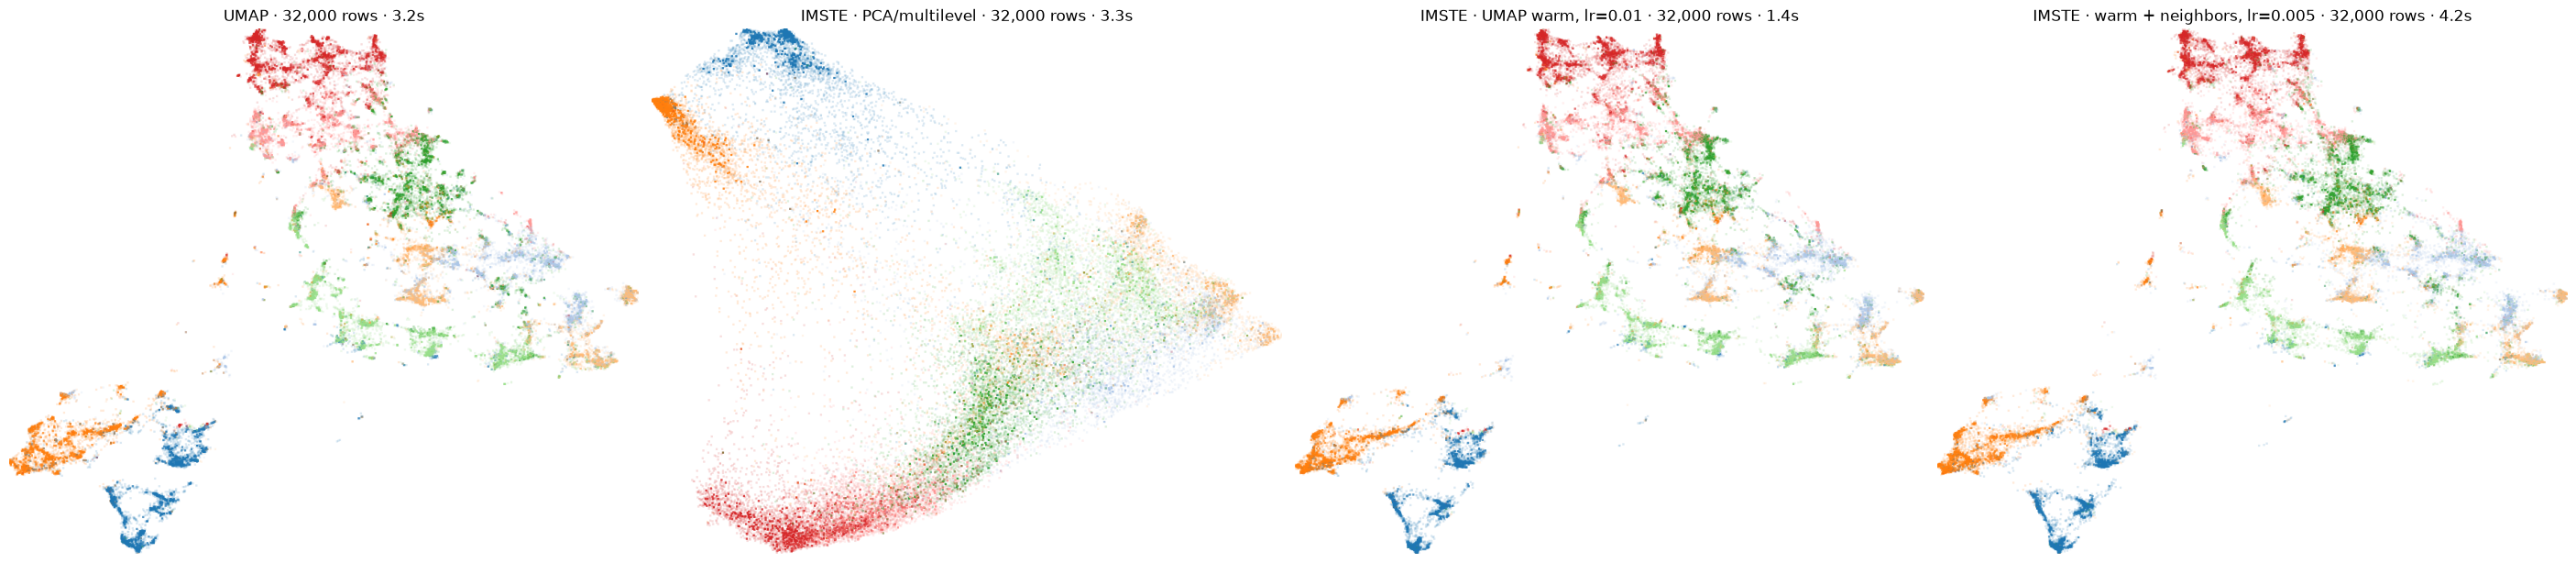

In [6]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from IPython.display import display
from imste.visualization import render_datashader_embedding

palette = plt.get_cmap("tab20")
class_order = list(labels_experiment.categories)
color_key = {label: to_hex(palette(i % palette.N)) for i, label in enumerate(class_order)}
label_values = pd.Series(np.asarray(labels_experiment)).astype(str)
layouts = [
    ("UMAP", Z_umap, umap_seconds),
    ("IMSTE · PCA/multilevel", Z_imste_multilevel, imste_multilevel_seconds),
    ("IMSTE · UMAP warm, lr=0.01", Z_imste_umap_warm_lr01, imste_umap_warm_lr01_seconds),
    ("IMSTE · warm + neighbors, lr=0.005", Z_imste_warm_knn_lr005, imste_warm_knn_lr005_seconds),
]
fig, axes = plt.subplots(1, len(layouts), figsize=(7 * len(layouts), 6), constrained_layout=True)
for ax, (name, coordinates, seconds) in zip(np.atleast_1d(axes), layouts):
    image = render_datashader_embedding(
        coordinates[:, :2], label_values, width=900, height=750,
        color_key=color_key, min_alpha=40, background="white", spread_px=1,
    )
    ax.imshow(image.to_pil())
    ax.set_title(f"{name} · {len(X_experiment):,} rows · {seconds:.1f}s")
    ax.set_axis_off()
display(fig)
plt.close(fig)
